Column 1: ['P21_c', 'P21_m', 'Pca2_1', 'Pbcn', 'P42_nmc', 'Pmn2_1', 'P4_nbm', 'P-43m', 'Fm-3m']
Column 2: ['0', '0.2072', '0.287', '0.3502', '0.4394', '0.4536', '0.5682', '0.5962', '0.8451']
Column 3: ['0', '0.2271', '0.2085', '0.6443', '0.314', '0.3771', '0.3818', '0.3983', '0.5646']
Column 4: ['0', '0.2452', '0.258', '0.4206', '0.3964', '0.4501', '0.4856', '0.5055', '0.6853']


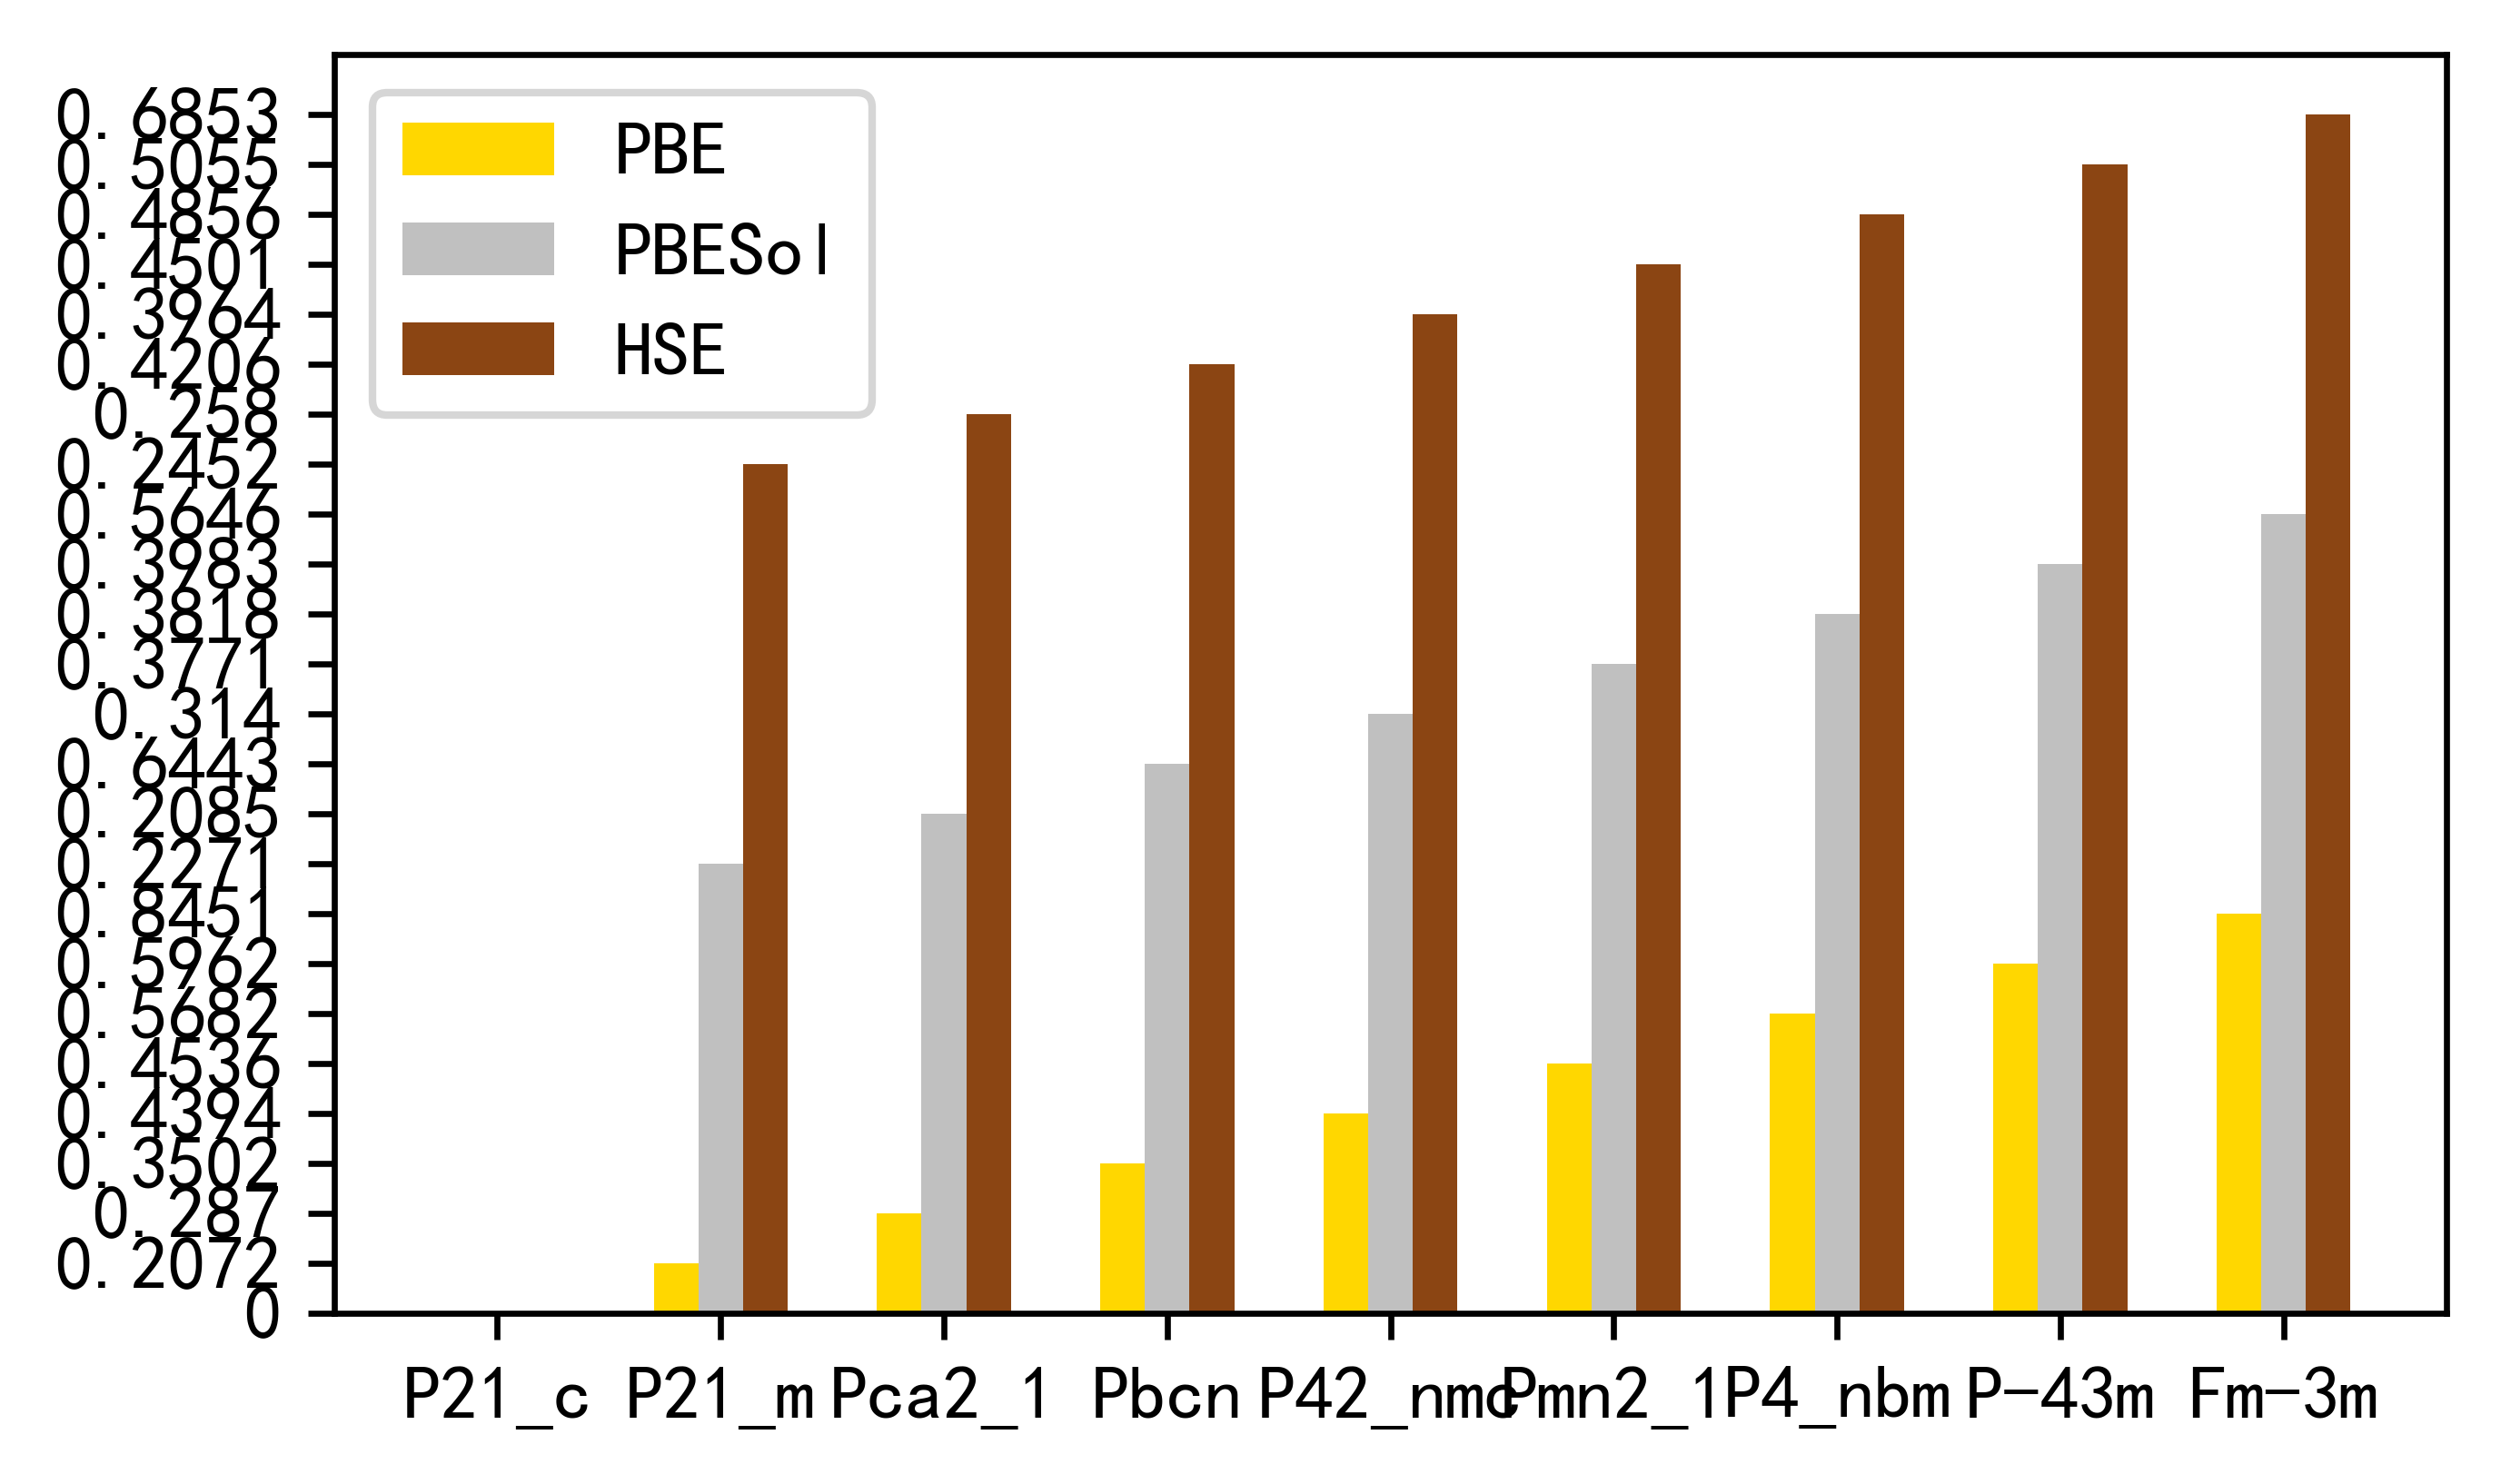

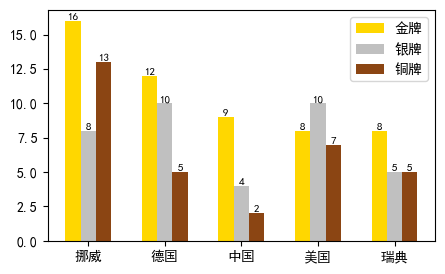

In [1]:
# 库导入
from matplotlib import pyplot as plt
import numpy as np
import csv
import pandas as pd

# ---------------------------
# Matplotlib 参数设置
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 600
plt.rcParams['figure.figsize'] = (5, 3)

# ---------------------------
# CSV 数据读取函数
def read_csv_as_columns(file_path):
    """
    Reads a CSV file with tab-separated values and returns each column as a list.
    Assumes the first row is a comment line and skips it.
    
    Parameters:
        file_path (str): Path to the CSV file.

    Returns:
        tuple: A tuple of four lists, each containing the data of one column.
    """
    phase, pbe, pbesol, hse = [], [], [], []

    with open(file_path, 'r') as file:
        reader = csv.reader(file, delimiter=',')
        next(reader)  # Skip the first row (comment line)

        for row in reader:
            if len(row) == 4:
                phase.append(row[0])
                pbe.append(row[1])
                pbesol.append(row[2])
                hse.append(row[3])
            else:
                print(f"Skipping row due to incorrect format: {row}")

    return phase, pbe, pbesol, hse

# Example CSV 文件路径
file_path = 'different_xc_energy_data.csv'  # 替换为你的实际路径
phase, pbe, pbesol, hse = read_csv_as_columns(file_path)

print("Column 1:", phase)
print("Column 2:", pbe)
print("Column 3:", pbesol)
print("Column 4:", hse)

# ---------------------------
# 使用 Pandas 重新排列 CSV 列顺序
df = pd.read_csv(file_path, skiprows=1, header=None)
df.columns = ['phase', 'pbe', 'pbesol', 'hse']
df = df[df.columns[::-1]]  # 反转列顺序
df.to_csv(file_path, index=False)

# ---------------------------
# 绘制 HfO2 各相能量柱状图
x = np.arange(len(phase))
width = 0.2

pbe_x = x
pbesol_x = x + width
hse_x = x + 2 * width

plt.bar(pbe_x, pbe, width=width, color="gold", label="PBE")
plt.bar(pbesol_x, pbesol, width=width, color="silver", label="PBESol")
plt.bar(hse_x, hse, width=width, color="saddlebrown", label="HSE")
plt.xticks(x + width, labels=phase)
plt.legend()
plt.show()

# ---------------------------
# 绘制国家奖牌柱状图示例
# 参数设置
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (5, 3)

countries = ['挪威', '德国', '中国', '美国', '瑞典']
gold_medal = [16, 12, 9, 8, 8]
silver_medal = [8, 10, 4, 10, 5]
bronze_medal = [13, 5, 2, 7, 5]

x = np.arange(len(countries))
width = 0.2

gold_x = x
silver_x = x + width
bronze_x = x + 2 * width

plt.bar(gold_x, gold_medal, width=width, color="gold", label="金牌")
plt.bar(silver_x, silver_medal, width=width, color="silver", label="银牌")
plt.bar(bronze_x, bronze_medal, width=width, color="saddlebrown", label="铜牌")

plt.xticks(x + width, labels=countries)

for i in range(len(countries)):
    plt.text(gold_x[i], gold_medal[i], gold_medal[i], va="bottom", ha="center", fontsize=8)
    plt.text(silver_x[i], silver_medal[i], silver_medal[i], va="bottom", ha="center", fontsize=8)
    plt.text(bronze_x[i], bronze_medal[i], bronze_medal[i], va="bottom", ha="center", fontsize=8)

plt.legend(loc="upper right")
plt.show()
